# Phase 7 — Moving obstacles

Two obstacles patrol fixed loops. The state becomes **(row, col, phase)** so the agent knows where the patrols are. Run from the `notebooks/` folder.

In [1]:
import sys, os
sys.path.append("..")
os.makedirs("../results", exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, Image

from env.dynamic_grid_env import DynamicGridEnv, MovingObstacle
from agents.q_learning import QLearningAgent, train, greedy_rollout
from agents.baselines import RandomAgent, AStarAgent
from evaluation import run_episode, compare, format_table, convergence_episode
from utils.plotting import plot_training
from utils.animate import animate_path, animate_agents

## 1. The environment

Same walls as before, plus two orange patrols. `period` is the number of steps before every patrol is back where it started; the phase `t mod period` is part of the state.

In [2]:
env = DynamicGridEnv()
print("state shape:", env.state_shape, "->", np.prod(env.state_shape), "states")
print("period:", env.period)
for m in env.movers:
    print("patrol:", m.path)

state shape: (10, 10, 4) -> 400 states
period: 4
patrol: [(2, 4), (2, 5), (2, 6), (2, 5)]
patrol: [(4, 9), (5, 9), (6, 9), (5, 9)]


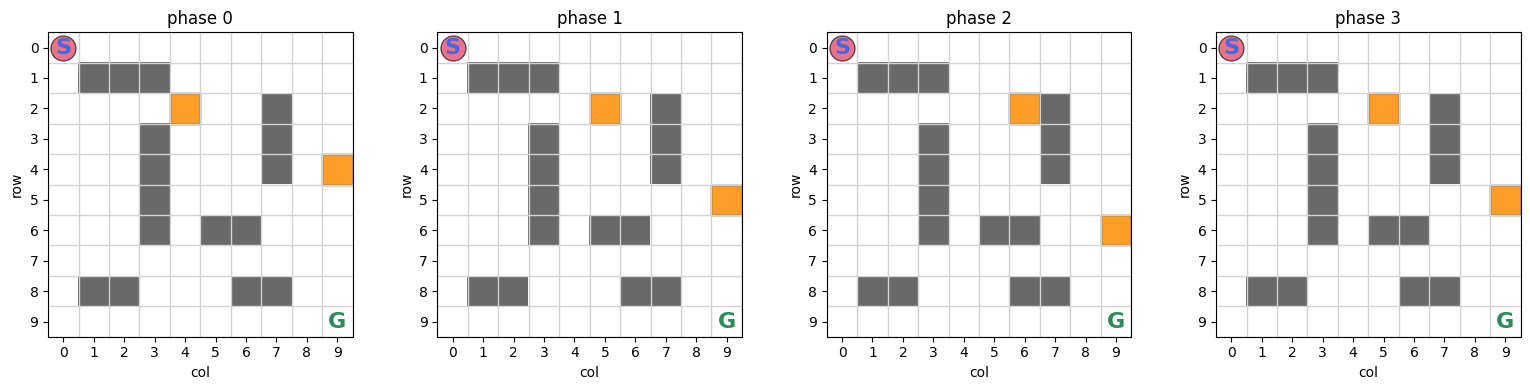

In [3]:
# The patrols at each phase of the cycle
fig, axes = plt.subplots(1, env.period, figsize=(4 * env.period, 4))
for ph, ax in enumerate(axes):
    env.reset(); env.t = ph
    env.render(ax=ax, show=False, title="")
    ax.set_title(f"phase {ph}")
plt.show()
env.reset();

### Why the phase is in the state

Stand at (2, 3) and look right. Whether stepping to (2, 4) is safe depends on where the patrol is — the *same cell* is fine at one moment and a collision the next. A table indexed only by (row, col) cannot tell those apart. Adding the phase makes the state *Markov* again: given (row, col, phase), the future is fully determined.

In [4]:
env.reset(); env.robot_pos = (2, 3)
for ph in range(env.period):
    env.t = ph
    print(f"phase {ph}: patrol now at {sorted(env.mover_cells())}, next at {sorted(env.mover_cells(ph + 1))}",
          "-> stepping RIGHT is", "BLOCKED" if (2, 4) in env.mover_cells(ph + 1) else "safe")
env.reset();

phase 0: patrol now at [(2, 4), (4, 9)], next at [(2, 5), (5, 9)] -> stepping RIGHT is safe
phase 1: patrol now at [(2, 5), (5, 9)], next at [(2, 6), (6, 9)] -> stepping RIGHT is safe
phase 2: patrol now at [(2, 6), (6, 9)], next at [(2, 5), (5, 9)] -> stepping RIGHT is safe
phase 3: patrol now at [(2, 5), (5, 9)], next at [(2, 4), (4, 9)] -> stepping RIGHT is BLOCKED


## 2. Collision rules

Robot moves first, then the patrols advance. Three ways to get hit, each costing −10 and leaving the robot where it was:

In [5]:
from env.grid_env import RIGHT, UP
tiny = DynamicGridEnv(obstacles=[], movers=[MovingObstacle([(0, 2), (0, 3)])])

def show(label, state, r, info):
    print(f"{label:28s} -> state {state}, reward {r:+.0f}, bumped_mover={info['bumped_mover']}")

tiny.reset()                                    # t=0: patrol (0,2) -> (0,3)
show("safe step",          *[x for i, x in enumerate(tiny.step(RIGHT)) if i != 2])
show("walk into patrol",   *[x for i, x in enumerate(tiny.step(RIGHT)) if i != 2])

tiny.reset(); tiny.robot_pos, tiny.t = (0, 2), 1   # patrol (0,3) -> (0,2)
show("swap places",        *[x for i, x in enumerate(tiny.step(RIGHT)) if i != 2])

tiny.reset(); tiny.robot_pos, tiny.t = (0, 2), 1
show("patrol runs into us", *[x for i, x in enumerate(tiny.step(UP)) if i != 2])

safe step                    -> state (0, 1, 1), reward -1, bumped_mover=False
walk into patrol             -> state (0, 1, 0), reward -10, bumped_mover=True
swap places                  -> state (0, 2, 0), reward -10, bumped_mover=True
patrol runs into us          -> state (0, 2, 0), reward -10, bumped_mover=True


## 3. Train

400 states instead of 100 (1600 Q-table entries instead of 400), so ε decays more slowly (0.998 per episode) and we run 3000 episodes. Still a few seconds on CPU.

In [6]:
agent = QLearningAgent(state_shape=env.state_shape, seed=0, epsilon_decay=0.998)
history = train(env, agent, n_episodes=3000, log_every=500, record_episodes=(1, 100, 500))
print("converged at episode", convergence_episode(history))

ep   500 | avg reward  -186.3 | avg steps   95.8 | success   80% | eps 0.368
ep  1000 | avg reward    60.1 | avg steps   25.8 | success  100% | eps 0.135
ep  1500 | avg reward    76.1 | avg steps   20.0 | success  100% | eps 0.050
ep  2000 | avg reward    79.0 | avg steps   19.2 | success  100% | eps 0.050
ep  2500 | avg reward    79.6 | avg steps   19.3 | success  100% | eps 0.050
ep  3000 | avg reward    79.1 | avg steps   19.2 | success  100% | eps 0.050
converged at episode 1167


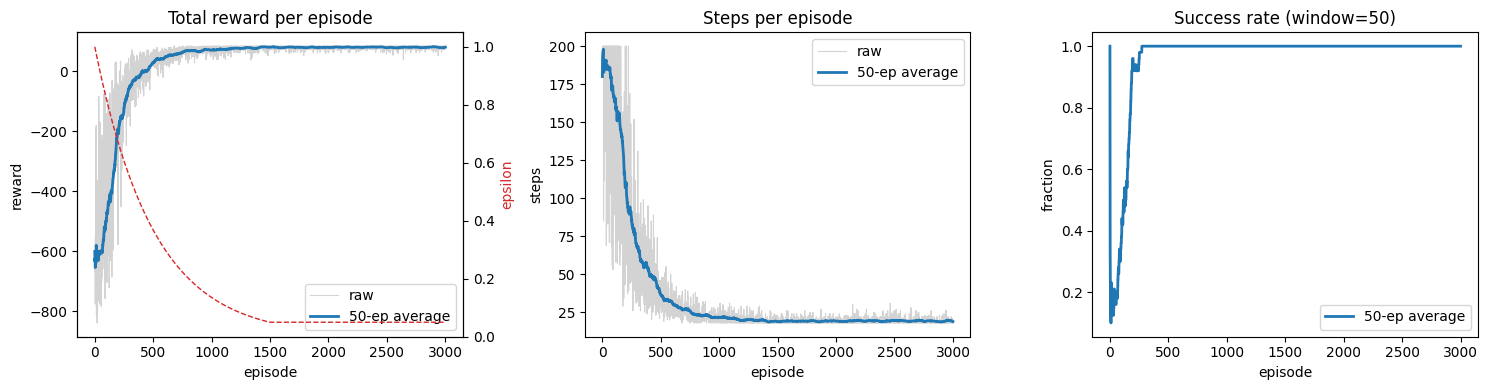

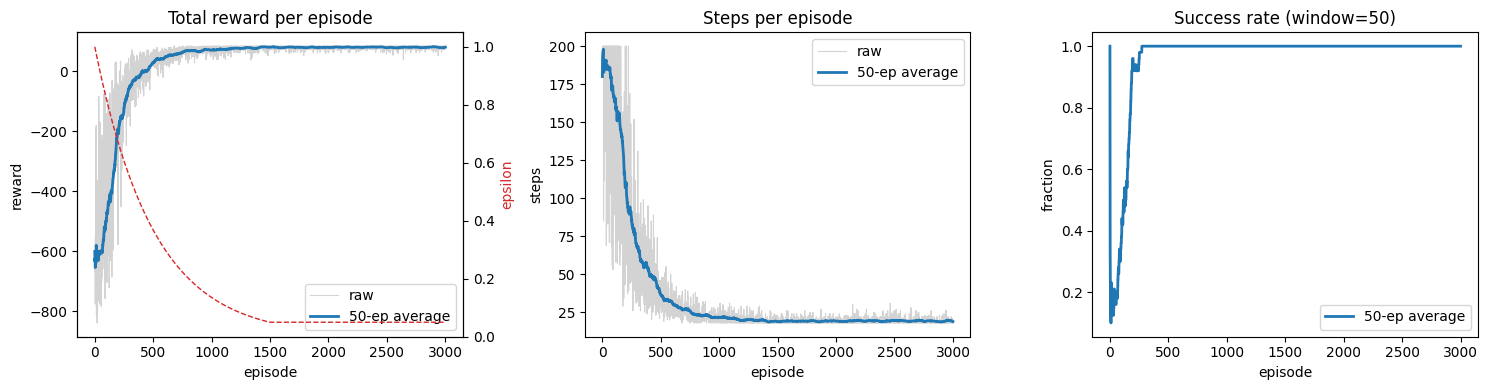

In [7]:
plot_training(history)

## 4. The learned route

A snapshot at t = 0. The route crosses both patrol corridors; the timing is only visible in the animation below.

greedy rollout: 18 steps, success = True


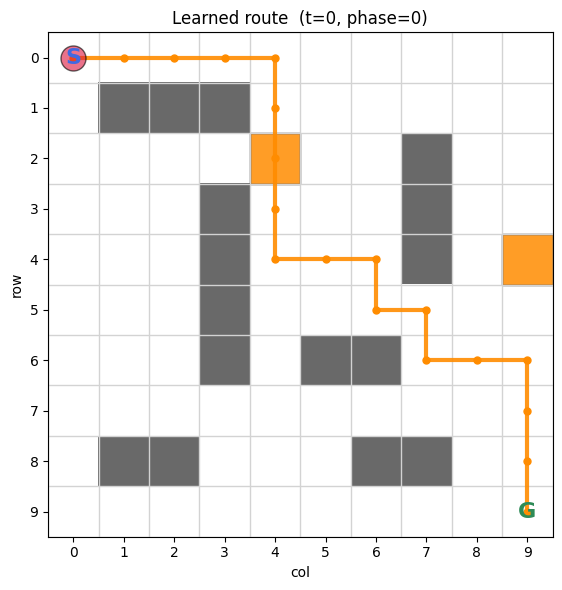

In [8]:
path, success = greedy_rollout(env, agent)
print(f"greedy rollout: {len(path) - 1} steps, success = {success}")
env.reset()
env.render(title="Learned route", path=path);

Watch the trained robot time its way past the patrols. Option A — GIF:

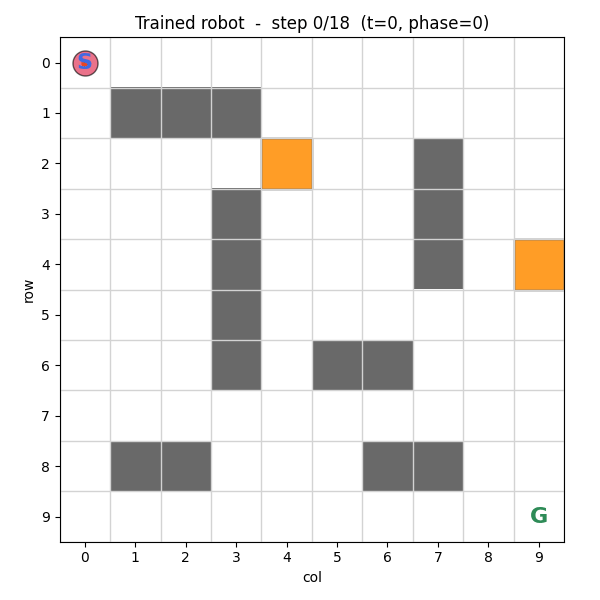

In [9]:
animate_path(env, path, save_path="../results/dynamic_robot_path.gif", title="Trained robot")
Image("../results/dynamic_robot_path.gif")

Option B — interactive player:

In [10]:
anim = animate_path(env, path, save_path=None, title="Trained robot")
HTML(anim.to_jshtml())

## 5. Early training, for contrast

In [11]:
ep = 100     # try 1 or 500
anim_early = animate_path(env, history["paths"][ep], save_path=None, interval_ms=120,
                          max_frames=80, title=f"Episode {ep}, eps={history['epsilon'][ep - 1]:.2f}")
HTML(anim_early.to_jshtml())

## 6. Random vs Q-learning vs A* (static map)

A* is given the walls but not the patrols — it plans the same 18-step route as before and walks into one. Q-learning learned the timing from rewards alone.

In [12]:
agents = {
    "Random": RandomAgent(seed=0),
    "Q-learning": agent,
    "A* (static map)": AStarAgent(env),
}
results = compare(env, agents, n_episodes=100)
print(format_table(results))

| Agent | Success | Avg steps | Avg reward | Avg collisions |
|---|---|---|---|---|
| Random | 18% | 189.6 | -689.6 | 57.6 |
| Q-learning | 100% | 18.0 | 83.0 | 0.0 |
| A* (static map) | 100% | 19.0 | 73.0 | 1.0 |


Random          : 200 steps
Q-learning      :  18 steps
A* (static map) :  19 steps


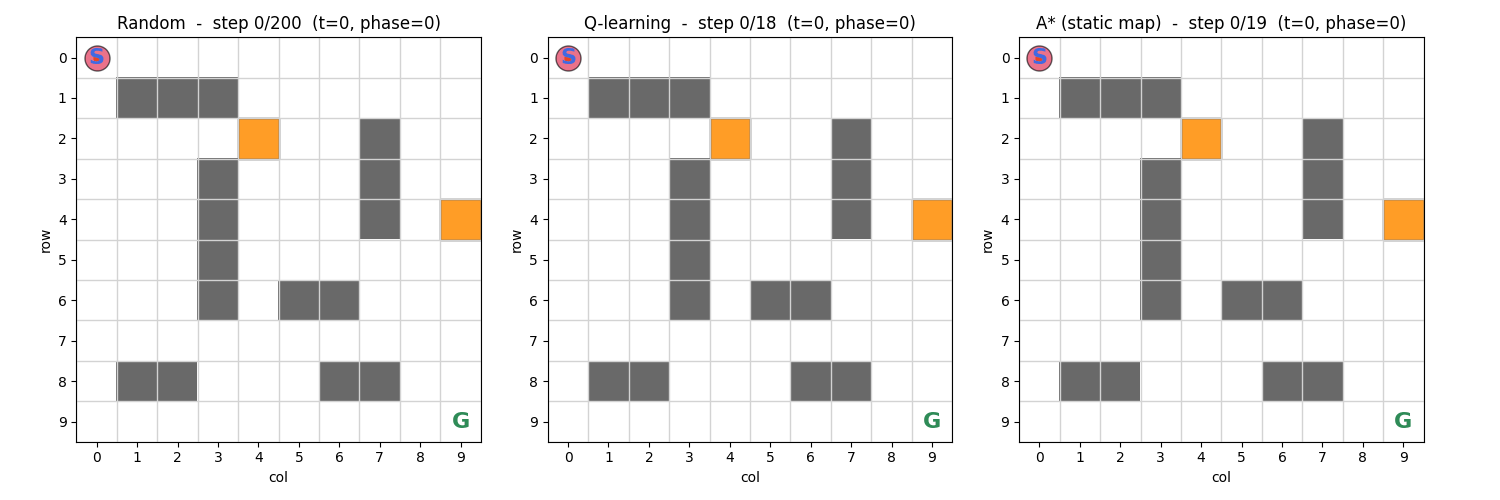

In [13]:
paths = {name: run_episode(env, ag, record_path=True)["path"] for name, ag in agents.items()}
for name, p in paths.items():
    print(f"{name:16s}: {len(p) - 1:3d} steps")
animate_agents(env, paths, save_path="../results/dynamic_agents.gif", max_frames=60)
Image("../results/dynamic_agents.gif")

In [14]:
anim_cmp = animate_agents(env, paths, save_path=None, max_frames=60)
HTML(anim_cmp.to_jshtml())

## 7. Static vs dynamic, side by side

How much did the patrols cost the learner? Train the Phase 4 agent on the plain grid for comparison.

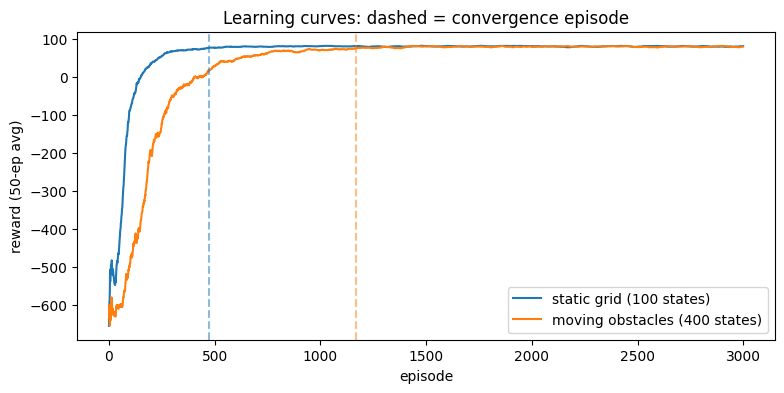

static converged at 474 | dynamic converged at 1167


In [15]:
from env.grid_env import GridEnv
static_env = GridEnv()
static_agent = QLearningAgent(grid_size=static_env.size, seed=0)
static_hist = train(static_env, static_agent, n_episodes=3000, log_every=0)

from utils.plotting import moving_average
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(moving_average(static_hist["reward"], 50), label="static grid (100 states)")
ax.plot(moving_average(history["reward"], 50), label="moving obstacles (400 states)")
ax.axvline(convergence_episode(static_hist), ls="--", c="C0", alpha=.5)
ax.axvline(convergence_episode(history), ls="--", c="C1", alpha=.5)
ax.set_xlabel("episode"); ax.set_ylabel("reward (50-ep avg)"); ax.legend(); ax.set_title("Learning curves: dashed = convergence episode")
plt.show()
print("static converged at", convergence_episode(static_hist), "| dynamic converged at", convergence_episode(history))